In [1]:
##############  Data Analysis      ################################################################


import os
import pandas as pd

# Specify the dataset path
dataset_path = '/Users/mac/Development/diploma/skin-mutation-detection/data/train'
image_directory = '/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input'

# Specify the ground truth file path
ground_file = '/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_GroundTruth.csv'
meta_file = '/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Metadata.csv'

if not os.path.exists(ground_file):
    print("Ground file not found in the dataset directory.")
else:
    print("########################################## Dataset Analysis ##########################################")
    
    # Read ground truth data
    ground = pd.read_csv(ground_file)
    
    # Columns representing labels
    label_columns = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
    
    # Check for missing values in ground truth
    missing_values_ground = ground.isnull().sum().sum()
    print(f"Missing values in ground truth: {missing_values_ground}")
    print("-----------------------------------------------------------------------------------")
    
    # Check for missing values in metadata
    missing_values_meta = 0
    if os.path.exists(meta_file):
        meta = pd.read_csv(meta_file)
        missing_values_meta = meta.isnull().sum().sum()
    print(f"Missing values in metadata: {missing_values_meta}")
    print("-----------------------------------------------------------------------------------")
    
    # Count the number of classes and images per class
    unique_classes = len(label_columns)
    class_counts = ground[label_columns].sum().to_dict()
    
    # Include "UNK" class in missing values if it has zero labels
    if class_counts['UNK'] == 0:
        missing_values_ground += 1
    
    # Check if the dataset is balanced
    avg_class_count = sum(class_counts.values()) / unique_classes
    is_balanced = all(abs(count - avg_class_count) <= 0.1 * avg_class_count for count in class_counts.values())
    
    # Check if the dataset is split into train, validation, and test sets
    dataset_splits = ['train', 'validation', 'test']
    dataset_split_info = {split: os.path.exists(os.path.join(dataset_path, split)) for split in dataset_splits}
    
    # Count total number of images per split
    split_image_counts = {}
    for split in dataset_splits:
        split_path = os.path.join(dataset_path, split)
        if os.path.exists(split_path):
            split_count = len([f for f in os.listdir(split_path) if f.endswith('.jpg')])
            split_image_counts[split] = split_count
            print(f"Total images in {split} split: {split_count}")
            print("-----------------------------------------------------------------------------------")
    
    # Count total images in the dataset image directory
    total_images_in_dataset = len([f for f in os.listdir(image_directory) if f.endswith('.jpg')]) if os.path.exists(image_directory) else 0
    
    # Print results separately
    print(f"Number of classes: {unique_classes}")
    print("-----------------------------------------------------------------------------------")
    print(f"Images per class: {class_counts}")
    print("-----------------------------------------------------------------------------------")
    print(f"Dataset is balanced: {is_balanced}")
    print("-----------------------------------------------------------------------------------")
    print(f"Dataset split exists: {dataset_split_info}")
    print("-----------------------------------------------------------------------------------")
    print(f"Total images per split: {split_image_counts}")
    print("-----------------------------------------------------------------------------------")
    print(f"Total number of images in the dataset directory: {total_images_in_dataset}")
    print("-----------------------------------------------------------------------------------")
    print("########################################## End of Analysis ##########################################")


########################################## Dataset Analysis ##########################################
Missing values in ground truth: 0
-----------------------------------------------------------------------------------
Missing values in metadata: 5536
-----------------------------------------------------------------------------------
Number of classes: 9
-----------------------------------------------------------------------------------
Images per class: {'MEL': 4522.0, 'NV': 12875.0, 'BCC': 3323.0, 'AK': 867.0, 'BKL': 2624.0, 'DF': 239.0, 'VASC': 253.0, 'SCC': 628.0, 'UNK': 0.0}
-----------------------------------------------------------------------------------
Dataset is balanced: False
-----------------------------------------------------------------------------------
Dataset split exists: {'train': False, 'validation': False, 'test': False}
-----------------------------------------------------------------------------------
Total images per split: {}
------------------------------

https://www.kaggle.com/code/khaledakram23/resnet50-befor

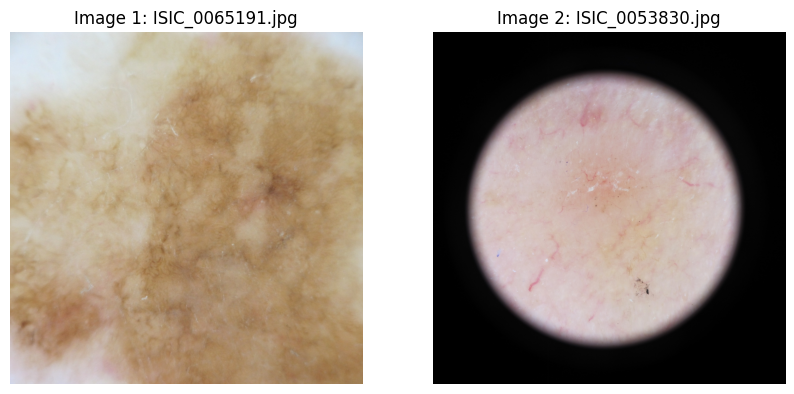

In [2]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

def display_random_images(dataset_path, num_images=2):
    # Get all image files in the dataset directory
    image_files = [f for f in os.listdir(dataset_path) if f.endswith('.jpg')]
    
    if len(image_files) < num_images:
        print(f"Not enough images in the directory. Found only {len(image_files)} images.")
        return
    
    # Randomly select images
    selected_images = random.sample(image_files, num_images)
    
    # Display the selected images
    plt.figure(figsize=(10, 5))
    
    for i, img_file in enumerate(selected_images):
        img_path = os.path.join(dataset_path, img_file)
        img = Image.open(img_path)
        
        plt.subplot(1, num_images, i + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Image {i + 1}: {img_file}")
    
    plt.show()

# Specify the path to the images directory
dataset_path = '/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input'
display_random_images(dataset_path, num_images=2)


In [3]:
import os
import pandas as pd

def analyze_ground_truth(dataset_path):
    try:
        ground_file = os.path.join(dataset_path, "ISIC_2019_Training_GroundTruth.csv")
        
        if not os.path.exists(ground_file):
            print("Ground truth file not found.")
            return
        
        # Read ground data
        ground = pd.read_csv(ground_file)
        
        # Columns representing labels
        label_columns = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
        
        # Check for missing values
        missing_values = ground.isnull().sum().sum()
        
        # Count the number of classes and images per class
        class_counts = ground[label_columns].sum().to_dict()
        
        print("Ground Truth Analysis:")
        print(f"Missing Values: {missing_values}")
        print(f"Number of Classes: {len(label_columns)}")
        print("Images per Class:")
        for label, count in class_counts.items():
            print(f"  {label}: {count}")

    except Exception as e:
        print(f"Error: {e}")


dataset_path = "/Users/mac/Development/diploma/skin-mutation-detection/data/train"
analyze_ground_truth(dataset_path)


Ground Truth Analysis:
Missing Values: 0
Number of Classes: 9
Images per Class:
  MEL: 4522.0
  NV: 12875.0
  BCC: 3323.0
  AK: 867.0
  BKL: 2624.0
  DF: 239.0
  VASC: 253.0
  SCC: 628.0
  UNK: 0.0


Ground Truth Analysis:
Missing Values: 0
Number of Classes: 9
Images per Class:
  MEL: 4522.0
  NV: 12875.0
  BCC: 3323.0
  AK: 867.0
  BKL: 2624.0
  DF: 239.0
  VASC: 253.0
  SCC: 628.0
  UNK: 0.0


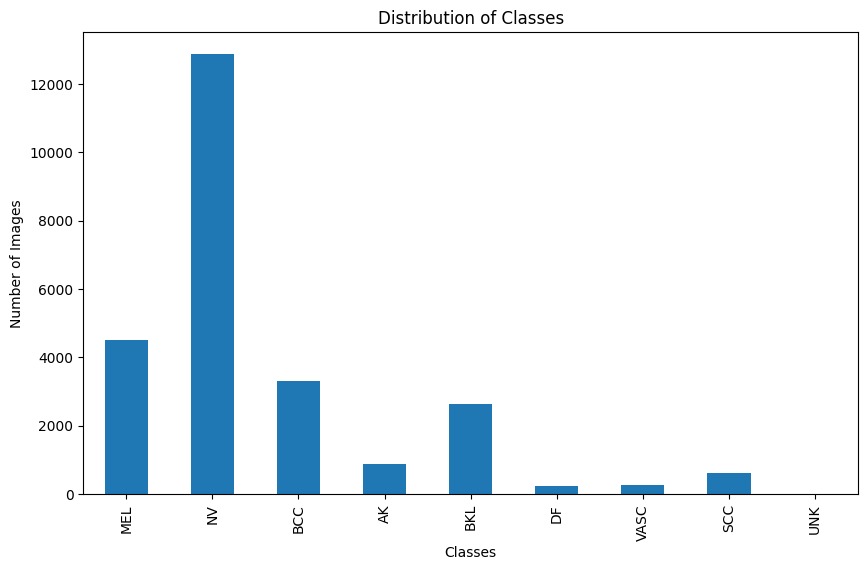

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def analyze_ground_truth(dataset_path):
    try:
        ground_file = os.path.join(dataset_path, "ISIC_2019_Training_GroundTruth.csv")
        
        if not os.path.exists(ground_file):
            print("Ground truth file not found.")
            return
        
        # Read ground data
        ground = pd.read_csv(ground_file)
        
        # Columns representing labels
        label_columns = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
        
        # Check for missing values
        missing_values = ground.isnull().sum().sum()
        
        # Count the number of classes and images per class
        class_counts = ground[label_columns].sum().to_dict()
        
        print("Ground Truth Analysis:")
        print(f"Missing Values: {missing_values}")
        print(f"Number of Classes: {len(label_columns)}")
        print("Images per Class:")
        for label, count in class_counts.items():
            print(f"  {label}: {count}")

        # Plot the distribution of each class
        ground.drop(columns=['image'], errors='ignore').sum().plot(kind='bar', figsize=(10, 6))
        plt.title("Distribution of Classes")
        plt.xlabel("Classes")
        plt.ylabel("Number of Images")
        plt.show()

    except Exception as e:
        print(f"Error: {e}")


dataset_path = "/Users/mac/Development/diploma/skin-mutation-detection/data/train"
analyze_ground_truth(dataset_path)


In [5]:
import os
import pandas as pd

def analyze_metadata(dataset_path):
    try:
        meta_file = os.path.join(dataset_path, "ISIC_2019_Training_Metadata.csv")
        
        if not os.path.exists(meta_file):
            print("Metadata file not found.")
            return
        
        # Read metadata
        metadata = pd.read_csv(meta_file)
        
        print("Metadata Columns:")
        print(metadata.columns.tolist())

        # Check for missing values
        missing_values = metadata.isnull().sum()
        print("\nMissing Values Per Column:")
        print(missing_values)

    except Exception as e:
        print(f"Error: {e}")


dataset_path = "/Users/mac/Development/diploma/skin-mutation-detection/data/train"
analyze_metadata(dataset_path)


Metadata Columns:
['image', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex']

Missing Values Per Column:
image                     0
age_approx              437
anatom_site_general    2631
lesion_id              2084
sex                     384
dtype: int64


In [6]:
import os
import pandas as pd

def remove_unk_column(dataset_path):
    try:
        ground_file = os.path.join(dataset_path, "ISIC_2019_Training_GroundTruth.csv")
        
        if not os.path.exists(ground_file):
            print("Ground truth file not found.")
            return
        
        # Read ground truth file
        ground = pd.read_csv(ground_file)
        
        # Print columns before removal
        print("Columns before removing 'UNK':")
        print(ground.columns.tolist())

        # Remove the "UNK" column if it exists
        if "UNK" in ground.columns:
            ground = ground.drop(columns=["UNK"])
        
        # Print columns after removal
        print("\nColumns after removing 'UNK':")
        print(ground.columns.tolist())

        # Save the updated version of the file to the working directory
        updated_file = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_GroundTruth_Updated.csv"
        ground.to_csv(updated_file, index=False)
        print(f"\nUpdated ground truth file saved as: {updated_file}")
        
        return ground  

    except Exception as e:
        print(f"Error: {e}")


# Example usage
dataset_path = "/Users/mac/Development/diploma/skin-mutation-detection/data/train"
remove_unk_column(dataset_path)


Columns before removing 'UNK':
['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']

Columns after removing 'UNK':
['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

Updated ground truth file saved as: /Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_GroundTruth_Updated.csv


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC
0,ISIC_0000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,ISIC_0000001,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,ISIC_0000002,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,ISIC_0000003,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,ISIC_0000004,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...
25326,ISIC_0073247,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
25327,ISIC_0073248,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
25328,ISIC_0073249,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25329,ISIC_0073251,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
import os
import pandas as pd

def clean_metadata(dataset_path):
    try:
        meta_file = os.path.join(dataset_path, "ISIC_2019_Training_Metadata.csv")
        
        if not os.path.exists(meta_file):
            print("Metadata file not found.")
            return
        
        # Read metadata
        metadata = pd.read_csv(meta_file)
        
        # Store original columns before modification
        original_columns = pd.DataFrame({"Columns Before Drop": metadata.columns.tolist()})
        
        # Drop 'lesion_id' column if it exists
        if "lesion_id" in metadata.columns:
            metadata = metadata.drop(columns=["lesion_id"])
        
        # Store modified columns after dropping 'lesion_id'
        modified_columns = pd.DataFrame({"Columns After Drop": metadata.columns.tolist()})
        
        # Concatenate for side-by-side display
        columns_comparison = pd.concat([original_columns, modified_columns], axis=1).fillna("")
        
        # Print column comparison table
        print("\n### Column Comparison Before and After Dropping 'lesion_id' ###")
        print(columns_comparison.to_string(index=False))

        # Identify correct column names
        age_col = "age_approx" if "age_approx" in metadata.columns else "age"
        sex_col = "sex"
        site_col = "anatom_site_general"

        # Store missing values before filling
        missing_before = metadata[[age_col, sex_col, site_col]].isnull().sum().to_frame("Missing Before")
        
        # Fill missing values
        metadata[age_col] = metadata[age_col].fillna(metadata[age_col].median())  # Fill age with median
        metadata[sex_col] = metadata[sex_col].fillna(metadata[sex_col].mode()[0])  # Fill sex with mode
        metadata[site_col] = metadata[site_col].fillna("Unknown")  # Fill site with 'Unknown'
        
        # Store missing values after filling
        missing_after = metadata[[age_col, sex_col, site_col]].isnull().sum().to_frame("Missing After")
        
        # Concatenate for side-by-side display
        missing_comparison = pd.concat([missing_before, missing_after], axis=1)
        
        # Print missing values before and after filling
        print("\n### Missing Values Before and After Filling ###")
        print(missing_comparison.to_string())

        return metadata  # Return cleaned DataFrame if needed for further use

    except Exception as e:
        print(f"Error: {e}")


dataset_path = "/Users/mac/Development/diploma/skin-mutation-detection/data/train"
clean_metadata(dataset_path)



### Column Comparison Before and After Dropping 'lesion_id' ###
Columns Before Drop  Columns After Drop
              image               image
         age_approx          age_approx
anatom_site_general anatom_site_general
          lesion_id                 sex
                sex                    

### Missing Values Before and After Filling ###
                     Missing Before  Missing After
age_approx                      437              0
sex                             384              0
anatom_site_general            2631              0


,image,age_approx,anatom_site_general,sex
0,ISIC_0000000,55.0,anterior torso,female
1,ISIC_0000001,30.0,anterior torso,female
2,ISIC_0000002,60.0,upper extremity,female
3,ISIC_0000003,30.0,upper extremity,male
4,ISIC_0000004,80.0,posterior torso,male
...,...,...,...,...
25326,ISIC_0073247,85.0,head/neck,female
25327,ISIC_0073248,65.0,anterior torso,male
25328,ISIC_0073249,70.0,lower extremity,male
25329,ISIC_0073251,55.0,palms/soles,female


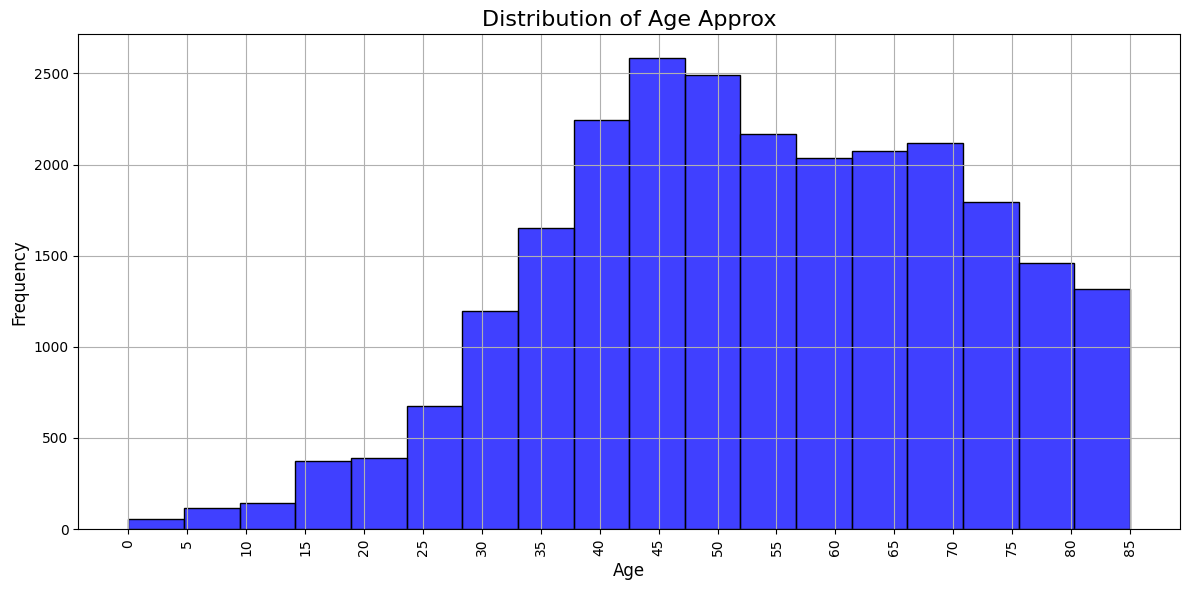

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_age_distribution(dataset_path):
    try:
        # Define the path to the metadata file
        meta_file = os.path.join(dataset_path, "ISIC_2019_Training_Metadata.csv")
        
        if not os.path.exists(meta_file):
            print("Metadata file not found.")
            return
        
        # Read metadata
        metadata = pd.read_csv(meta_file)
        
        # Check for the 'age_approx' column or fall back to 'age'
        age_col = "age_approx" if "age_approx" in metadata.columns else "age"
        
        # Ensure the age column exists in the dataset
        if age_col not in metadata.columns:
            print(f"Column '{age_col}' not found in the dataset.")
            return
        
        # Plot the distribution of the age column
        plt.figure(figsize=(12, 6))
        sns.histplot(metadata[age_col], kde=False, bins=len(metadata[age_col].dropna().unique()), color='blue')

        # Customize the X-axis to show all unique ages
        unique_ages = sorted(metadata[age_col].dropna().unique())
        plt.xticks(unique_ages, rotation=90)  # Rotate to fit the ticks
        
        plt.title(f"Distribution of {age_col.replace('_', ' ').title()}", fontsize=16)
        plt.xlabel("Age", fontsize=12)
        plt.ylabel("Frequency", fontsize=12)
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error: {e}")


dataset_path = "/Users/mac/Development/diploma/skin-mutation-detection/data/train"
plot_age_distribution(dataset_path)


/var/folders/vz/rgbmjfqn0nq0nvl3m3c5by_00000gn/T/ipykernel_6659/1366979750.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sex_counts.index, y=sex_counts.values, palette="coolwarm")


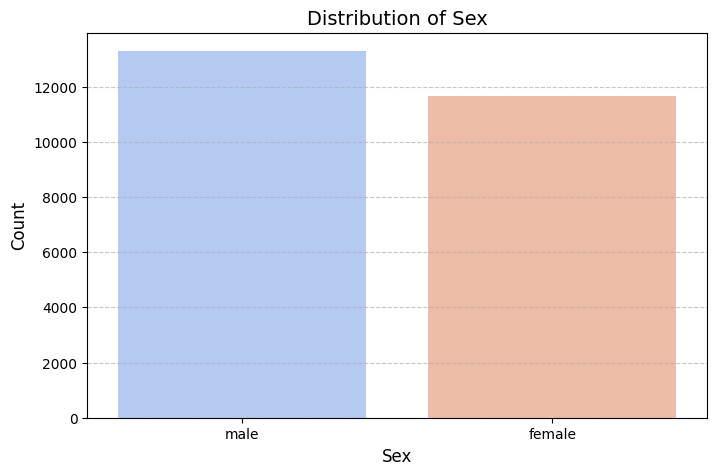

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_sex_distribution(dataset_path):
    try:
        # Define the path to the metadata file
        meta_file = os.path.join(dataset_path, "ISIC_2019_Training_Metadata.csv")
        
        if not os.path.exists(meta_file):
            print("Metadata file not found.")
            return
        
        # Read metadata
        metadata = pd.read_csv(meta_file)
        
        # Ensure 'sex' column exists
        if "sex" not in metadata.columns:
            print("Column 'sex' not found in the dataset.")
            return
        
        # Count occurrences of each sex category
        sex_counts = metadata["sex"].value_counts()

        # Plot
        plt.figure(figsize=(8, 5))
        sns.barplot(x=sex_counts.index, y=sex_counts.values, palette="coolwarm")

        plt.title("Distribution of Sex", fontsize=14)
        plt.xlabel("Sex", fontsize=12)
        plt.ylabel("Count", fontsize=12)
        plt.xticks(rotation=0)
        plt.grid(axis="y", linestyle="--", alpha=0.7)

        plt.show()

    except Exception as e:
        print(f"Error: {e}")


dataset_path = "/Users/mac/Development/diploma/skin-mutation-detection/data/train"
plot_sex_distribution(dataset_path)


/var/folders/vz/rgbmjfqn0nq0nvl3m3c5by_00000gn/T/ipykernel_6659/4065426237.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=site_counts.index, y=site_counts.values, palette="viridis")


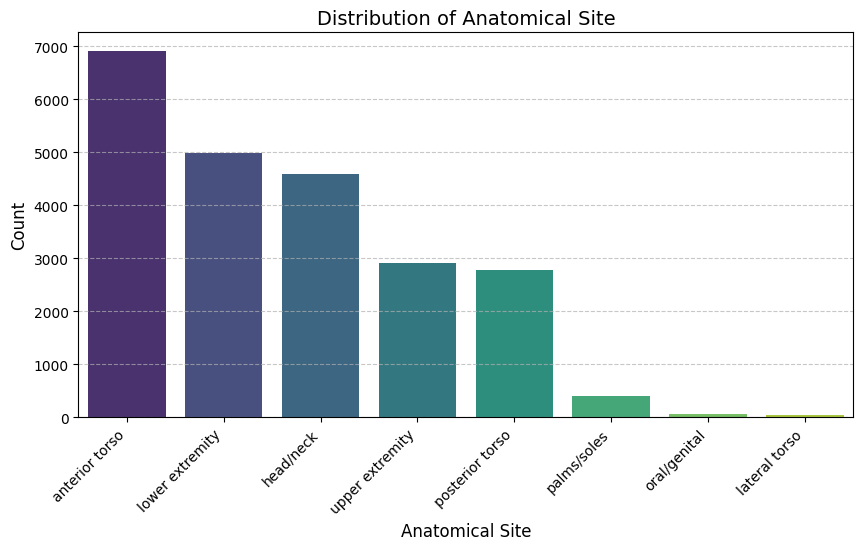

In [10]:
def plot_anatom_site_distribution(dataset_path):
    try:
        # Define the path to the metadata file
        meta_file = os.path.join(dataset_path, "ISIC_2019_Training_Metadata.csv")
        
        if not os.path.exists(meta_file):
            print("Metadata file not found.")
            return
        
        # Read metadata
        metadata = pd.read_csv(meta_file)
        
        # Ensure 'anatom_site_general' column exists
        if "anatom_site_general" not in metadata.columns:
            print("Column 'anatom_site_general' not found in the dataset.")
            return
        
        # Count occurrences of each anatomical site category
        site_counts = metadata["anatom_site_general"].value_counts()

        # Plot
        plt.figure(figsize=(10, 5))
        sns.barplot(x=site_counts.index, y=site_counts.values, palette="viridis")

        plt.title("Distribution of Anatomical Site", fontsize=14)
        plt.xlabel("Anatomical Site", fontsize=12)
        plt.ylabel("Count", fontsize=12)
        plt.xticks(rotation=45, ha="right")  # Rotate for better readability
        plt.grid(axis="y", linestyle="--", alpha=0.7)

        plt.show()

    except Exception as e:
        print(f"Error: {e}")


plot_anatom_site_distribution(dataset_path)


In [11]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [12]:
!pip install tensorflow numpy opencv-python matplotlib

In [13]:
# Load the CSV containing the image file names and labels
df = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_GroundTruth.csv')
df.drop(columns=['UNK'], 
        inplace=True)

test_df = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_Test_GroundTruth_Updated.csv')

# Convert all columns except 'image' to numeric
df.iloc[:, 1:] = df.iloc[:, 1:].apply(pd.to_numeric, errors='coerce')
test_df.iloc[:, 1:] = test_df.iloc[:, 1:].apply(pd.to_numeric, errors='coerce')

# Create a new column 'label' based on the columns with cancer types
df['label'] = df.iloc[:, 1:].idxmax(axis=1)
test_df['label'] = test_df.iloc[:, 1:].idxmax(axis=1)

# Verify the new 'label' column
print(df['label'].value_counts())
print(test_df['label'].value_counts())


label
NV      12875
MEL      4522
BCC      3323
BKL      2624
AK        867
SCC       628
VASC      253
DF        239
Name: count, dtype: int64
label
NV      6705
MEL     1113
BKL     1099
BCC      514
AK       327
VASC     142
DF       115
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle

train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

test_df = shuffle(test_df, random_state=42)

# Print the sizes of each set
print(f"Train set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

# Save the splits as CSV files if needed
train_df.to_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/train.csv', index=False)
val_df.to_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/val.csv', index=False)
test_df.to_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/test.csv', index=False)

print("Files saved successfully!")


Train set size: 20264
Validation set size: 5067
Test set size: 10015
Files saved successfully!


In [15]:
import os
import tensorflow as tf
import numpy as np
import pandas as pd

# Load and preprocess images
def load_image(image_path):
    try:
        image = tf.io.read_file(image_path)
        image = tf.image.decode_jpeg(image, channels=3)  # Decode the image to RGB
        image = tf.image.resize(image, [224, 224])  # Resize to 224x224 (common input size for MobileNetV2)
        image = image / 255.0  # Normalize image to [0, 1]
        return image
    except Exception as e:
        print(f"Error loading image {image_path}: {e}")
        return None

# Check if the image exists in the directory
def check_images(image_dir):
    image_files = []
    for root, dirs, files in os.walk(image_dir):
        for file in files:
            if file.endswith(('.jpg', '.jpeg', '.png')):  
                image_files.append(os.path.join(root, file))
    print(f"Found {len(image_files)} image files in the directory.")
    return image_files

# dataset paths
image_dir = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"
image_files = check_images(image_dir)

# Test loading the first image from the directory
if len(image_files) > 0:
    image_path = image_files[0] 
    image = load_image(image_path)
    if image is not None:
        print("Image loaded successfully")
    else:
        print("Image loading failed")
else:
    print("No images found in the directory")

Found 25331 image files in the directory.
Image loaded successfully


2025-03-02 20:45:30.749461: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-03-02 20:45:30.749486: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-03-02 20:45:30.749489: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1740941130.749505  224147 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1740941130.749523  224147 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [16]:
import pandas as pd
import os

# Define the path to  dataset CSV and image directory
CSV_PATHS = {
    'train': '/Users/mac/Development/diploma/skin-mutation-detection/data/train/train.csv',
    'val': '/Users/mac/Development/diploma/skin-mutation-detection/data/train/val.csv',
    'test': '/Users/mac/Development/diploma/skin-mutation-detection/data/train/test.csv'
}
IMAGE_DIR = '/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input/'  
IMAGE_EXT = '.jpg' 

def check_dataset(csv_path, image_dir, image_ext):
    # Load the dataset
    df = pd.read_csv(csv_path)
    
    # Check if the 'label' column exists and is not empty
    if 'label' not in df.columns:
        print(f"Error: 'label' column is missing in {csv_path}.")
        return
    if df['label'].isnull().sum() > 0:
        print(f"Found {df['label'].isnull().sum()} images without labels in {csv_path}.")
    else:
        print(f"All images have labels in {csv_path}.")
    
    # Add full image paths to the DataFrame
    df['image'] = image_dir + df['image'] + image_ext
    
    # Print some paths for debugging
    print(f"Sample paths from {csv_path}:")
    print(df['image'].head())
    
    # Check if image files exist
    missing_files = df[~df['image'].apply(lambda x: os.path.exists(x))]
    if not missing_files.empty:
        print(f"Found {len(missing_files)} missing image files in {csv_path}.")
    else:
        print(f"All image files are present in {csv_path}.")

# Check all datasets
for dataset, csv_path in CSV_PATHS.items():
    print(f"\nChecking {dataset} dataset...")
    check_dataset(csv_path, IMAGE_DIR, IMAGE_EXT)


Checking train dataset...
All images have labels in /Users/mac/Development/diploma/skin-mutation-detection/data/train/train.csv.
Sample paths from /Users/mac/Development/diploma/skin-mutation-detection/data/train/train.csv:
0    /Users/mac/Development/diploma/skin-mutation-d...
1    /Users/mac/Development/diploma/skin-mutation-d...
2    /Users/mac/Development/diploma/skin-mutation-d...
3    /Users/mac/Development/diploma/skin-mutation-d...
4    /Users/mac/Development/diploma/skin-mutation-d...
Name: image, dtype: object
All image files are present in /Users/mac/Development/diploma/skin-mutation-detection/data/train/train.csv.

Checking val dataset...
All images have labels in /Users/mac/Development/diploma/skin-mutation-detection/data/train/val.csv.
Sample paths from /Users/mac/Development/diploma/skin-mutation-detection/data/train/val.csv:
0    /Users/mac/Development/diploma/skin-mutation-d...
1    /Users/mac/Development/diploma/skin-mutation-d...
2    /Users/mac/Development/diploma/

In [17]:
!pip install tensorflow-metal

In [18]:
import tensorflow as tf
print("Num GPUs Available:", tf.config.list_physical_devices())

Num GPUs Available: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf


from tensorflow.keras.applications import ResNet50, ResNet152, ResNet101
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, EarlyStopping
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder

# Define image dimensions and paths
IMG_HEIGHT, IMG_WIDTH = 336, 336
BATCH_SIZE = 32
EPOCHS = 50
TRAIN_IMAGE_DIR = '/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input/'
TEST_IMAGE_DIR = '/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12'

IMAGE_EXT = '.jpg'

# Load dataset CSV files
train_df = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/train.csv')
val_df = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/val.csv')
test_df = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/test.csv')

# Add full image paths to the DataFrame
train_df['image_path'] = TRAIN_IMAGE_DIR + train_df['image'] + IMAGE_EXT
val_df['image_path'] = TRAIN_IMAGE_DIR + val_df['image'] + IMAGE_EXT
test_df['image_path'] = TEST_IMAGE_DIR + test_df['image'] + IMAGE_EXT

# Encode the labels
label_encoder = LabelEncoder()
train_df['label'] = label_encoder.fit_transform(train_df['label'])
val_df['label'] = label_encoder.transform(val_df['label'])
test_df['label'] = label_encoder.transform(test_df['label'])

# Ensure labels are of type int32
train_df['label'] = train_df['label'].astype('int32')
val_df['label'] = val_df['label'].astype('int32')
test_df['label'] = test_df['label'].astype('int32')

# Functions to load image and label
def load_image_and_label(file_path, label):
    image = load_img(file_path.numpy().decode('utf-8'), target_size=(IMG_HEIGHT, IMG_WIDTH))
    image = img_to_array(image) / 255.0
    return image, label

def load_image_and_label_wrapper(file_path, label):
    image, label = tf.py_function(load_image_and_label, [file_path, label], [tf.float32, tf.int32])
    image.set_shape((IMG_HEIGHT, IMG_WIDTH, 3))
    label.set_shape(())
    return image, label

def df_to_dataset(df):
    file_paths = df['image_path'].values
    labels = df['label'].values
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    dataset = dataset.map(load_image_and_label_wrapper, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.repeat()
    return dataset

# Create datasets
train_dataset = df_to_dataset(train_df).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_dataset = df_to_dataset(val_df).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_dataset = df_to_dataset(test_df).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Load ResNet50 model
base_model = ResNet101(weights='imagenet', include_top=False, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))

# Unfreeze more layers (keep only the first 40 frozen)
base_model.trainable = True
for layer in base_model.layers[:40]:  # Freeze the first 40 layers
    layer.trainable = False

# Add custom layers on top
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)  # Add a dense layer
x = Dropout(0.5)(x)  # Increased dropout rate
x = Dense(512, activation='relu')(x)  # Add an intermediate dense layer
x = Dropout(0.5)(x)  # Additional dropout for regularization
x = BatchNormalization()(x)  # Add Batch Normalization layer
predictions = Dense(8, activation='softmax')(x)  # 8 classes
model = Model(inputs=base_model.input, outputs=predictions)

model_path = 'best_model.keras'

# if os.path.exists(model_path):
    # model = load_model(model_path)

# Define callbacks
checkpoint = ModelCheckpoint(model_path, monitor='val_accuracy', save_best_only=True, mode='max')
early_stopping = EarlyStopping(monitor='val_accuracy', patience=5, mode='max', restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_accuracy', factor=0.2, patience=3, min_lr=0.000001)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.00001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    steps_per_epoch=len(train_df) // BATCH_SIZE,
    validation_steps=len(val_df) // BATCH_SIZE,
    callbacks=[checkpoint, early_stopping, reduce_lr]
)

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(test_dataset, steps=len(test_df) // BATCH_SIZE)
print(f'Test accuracy with Adam: {test_accuracy}')


2025-03-02 22:14:24.068312: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-03-02 22:14:24.068345: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-03-02 22:14:24.068349: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1740946464.068362  289897 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1740946464.068381  289897 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 18s 0us/step
Epoch 1/50


2025-03-02 22:14:57.003856: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


633/633 ━━━━━━━━━━━━━━━━━━━━ 1398s 2s/step - accuracy: 0.2721 - loss: 2.3140 - val_accuracy: 0.5797 - val_loss: 1.3800 - learning_rate: 1.0000e-05
Epoch 2/50
633/633 ━━━━━━━━━━━━━━━━━━━━ 1303s 2s/step - accuracy: 0.5580 - loss: 1.5003 - val_accuracy: 0.6768 - val_loss: 1.0582 - learning_rate: 1.0000e-05
Epoch 3/50
633/633 ━━━━━━━━━━━━━━━━━━━━ 9321s 15s/step - accuracy: 0.6290 - loss: 1.2204 - val_accuracy: 0.6924 - val_loss: 0.9675 - learning_rate: 1.0000e-05
Epoch 4/50
633/633 ━━━━━━━━━━━━━━━━━━━━ 13321s 21s/step - accuracy: 0.6794 - loss: 1.0219 - val_accuracy: 0.7059 - val_loss: 0.9411 - learning_rate: 1.0000e-05
Epoch 5/50
633/633 ━━━━━━━━━━━━━━━━━━━━ 13399s 21s/step - accuracy: 0.7277 - loss: 0.8464 - val_accuracy: 0.7081 - val_loss: 0.9405 - learning_rate: 1.0000e-05
Epoch 6/50
633/633 ━━━━━━━━━━━━━━━━━━━━ 1391s 2s/step - accuracy: 0.7850 - loss: 0.6686 - val_accuracy: 0.7091 - val_loss: 1.0395 - learning_rate: 1.0000e-05
Epoch 7/50
633/633 ━━━━━━━━━━━━━━━━━━━━ 1394s 2s/step - ac

KeyboardInterrupt: 

In [3]:
import pandas as pd
import tensorflow as tf
import os
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from sklearn.preprocessing import LabelEncoder

# Define paths
CSV_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_GroundTruth.csv"
IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_Input/"
IMAGE_EXT = ".jpg"
MODEL_PATH = "saved_model.keras"

# Image parameters
IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 32

# Load test dataset
test_df = pd.read_csv(CSV_PATH)
test_df.drop(columns=['score_weight','validation_weight'], inplace=True)
# Convert all columns except 'image' to numeric
test_df.iloc[:, 1:] = test_df.iloc[:, 1:].apply(pd.to_numeric, errors='coerce')
# Create a new column 'label' based on the columns with cancer types
test_df['label'] = test_df.iloc[:, 1:].idxmax(axis=1)

# Encode labels as integers
label_encoder = LabelEncoder()
test_df['label'] = label_encoder.fit_transform(test_df['label'])

test_df['image_path'] = IMAGE_DIR + test_df['image'] + IMAGE_EXT

def load_image_and_label(file_path, label):
    image = load_img(file_path.numpy().decode('utf-8'), target_size=(IMG_HEIGHT, IMG_WIDTH))
    image = img_to_array(image) / 255.0
    return image, label

def load_image_and_label_wrapper(file_path, label):
    image, label = tf.py_function(load_image_and_label, [file_path, label], [tf.float32, tf.int64])
    image.set_shape((IMG_HEIGHT, IMG_WIDTH, 3))
    label.set_shape(())
    return image, label

def df_to_dataset(df):
    file_paths = df['image_path'].values
    labels = df['label'].values
    dataset = tf.data.Dataset.from_tensor_slices((file_paths, labels))
    dataset = dataset.map(load_image_and_label_wrapper, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

# Create test dataset
test_dataset = df_to_dataset(test_df)

# Load trained model
model = tf.keras.models.load_model(MODEL_PATH)

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(test_dataset, steps=len(test_df) // BATCH_SIZE)
print(f'Test accuracy: {test_accuracy}')


257/257 ━━━━━━━━━━━━━━━━━━━━ 57s 194ms/step - accuracy: 0.5534 - loss: 2.1294
Test accuracy: 0.44832199811935425


In [ ]:
!pip install tabulate

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


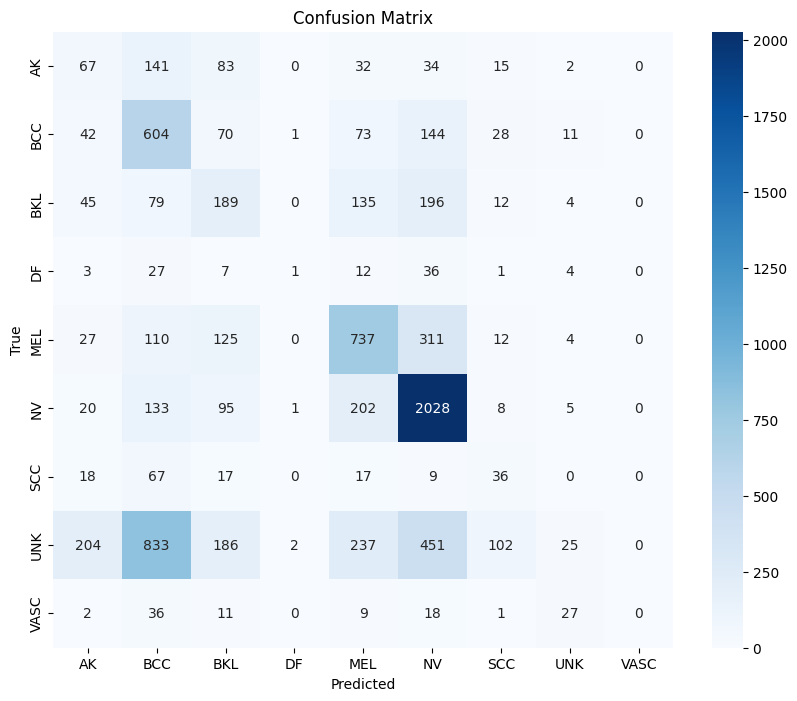

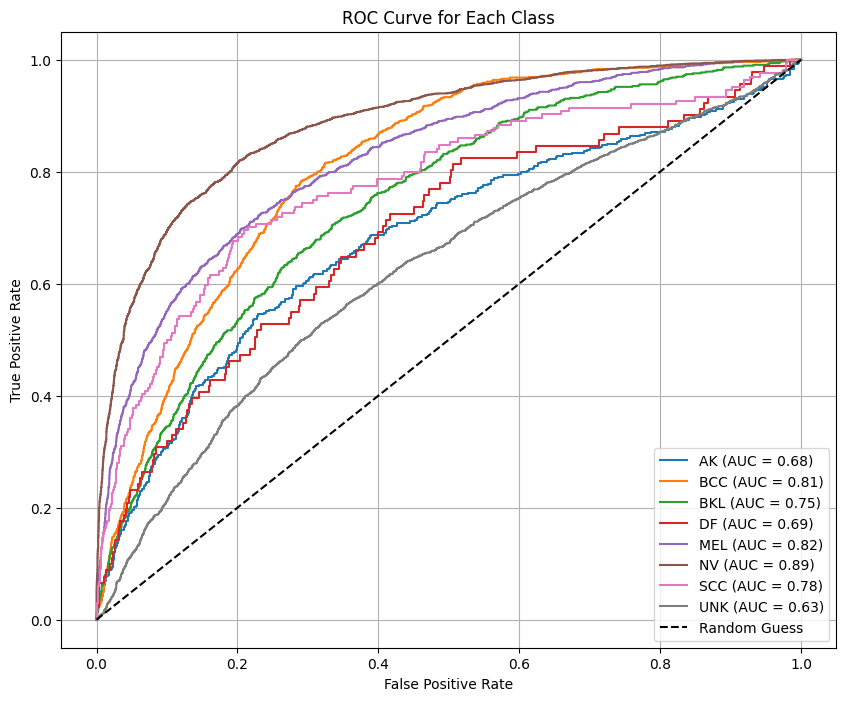

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_curve, roc_auc_score
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns

# Function to get predictions and true labels
def get_predictions_and_labels(model, dataset):
    y_true = []
    y_pred = []
    y_pred_proba = []
    for images, labels in dataset.take(len(test_df) // BATCH_SIZE):
        predictions = model.predict(images)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(predictions, axis=1))
        y_pred_proba.extend(predictions)
    return np.array(y_true), np.array(y_pred), np.array(y_pred_proba)

# Get predictions, true labels, and predicted probabilities
y_true, y_pred, y_pred_proba = get_predictions_and_labels(model, test_dataset)

# Print evaluation metrics message
print("==============================================")
print("          Model Evaluation Metrics           ")
print("==============================================")

# Calculate overall accuracy
accuracy = accuracy_score(y_true, y_pred)

# Calculate precision, recall, and F1 score for each class
precision = precision_score(y_true, y_pred, average=None)
recall = recall_score(y_true, y_pred, average=None)
f1 = f1_score(y_true, y_pred, average=None)

# Calculate accuracy for each class
class_accuracy = []
class_counts = []  # To store the count of images in each class
for i in range(len(label_encoder.classes_)):
    class_mask = y_true == i
    class_accuracy.append(accuracy_score(y_true[class_mask], y_pred[class_mask]))
    class_counts.append(np.sum(class_mask))  # Count the number of images in each class

# Create a table for class-wise metrics
metrics_table = []
for i, class_name in enumerate(label_encoder.classes_):  
    metrics_table.append([class_name, precision[i], recall[i], f1[i], class_accuracy[i], class_counts[i]])

# Add overall accuracy to the table
metrics_table.append(["Overall", "-", "-", "-", accuracy, "-"])

# Print the table
print("\nClass-wise Metrics:")
print(tabulate(metrics_table, headers=["Class", "Precision", "Recall", "F1 Score", "Accuracy", "Image Count"], tablefmt="pretty", floatfmt=".4f"))

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# ROC Curve for each class
plt.figure(figsize=(10, 8))
for i in range(8):  #  8 classes
    fpr, tpr, _ = roc_curve(y_true == i, y_pred_proba[:, i])
    auc_score = roc_auc_score(y_true == i, y_pred_proba[:, i])
    plt.plot(fpr, tpr, label=f'{label_encoder.classes_[i]} (AUC = {auc_score:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Each Class')
plt.legend(loc='lower right')
plt.grid()
plt.show()




In [ ]:
model.save('saved_model.keras')
print("Model saved successfully!")
 

Model saved successfully!


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt

# Define the image size
IMG_HEIGHT = 224  
IMG_WIDTH = 224

# Load trained model
model = tf.keras.models.load_model("/Users/mac/Development/diploma/skin-mutation-detection/data/train/saved_model.keras")  

def predict_image(model, image_path):
    # Load and preprocess the image
    image = load_img(image_path, target_size=(IMG_HEIGHT, IMG_WIDTH))
    image = img_to_array(image) / 255.0
    image = tf.expand_dims(image, axis=0)  # Add batch dimension

    # Make prediction
    predictions = model.predict(image)
    predicted_class = tf.argmax(predictions[0]).numpy()  # Get the index of the highest probability
    confidence = tf.reduce_max(predictions[0]).numpy()  # Get the highest confidence score
    
    # Map the predicted class to benign or malignant
    malignant_classes = [0, 1, 2, 3]  # malignant classes
    benign_classes = [4, 5, 6, 7]  # benign classes
    
    if predicted_class in benign_classes:
        class_type = "Benign"
    else:
        class_type = "Malignant"
    
    # List of class names for detailed classification
    class_names = [
        "Basal Cell Carcinoma (BCC)", "Squamous Cell Carcinoma (SCC)", "Melanoma (MEL)", 
        "Actinic Keratosis (AK)", "Benign Nevus (NV)", "Vascular Lesions (VASC)", 
        "Benign Keratosis (BKL)", "Dermatofibroma (DF)"
    ]
    
    # Get the detailed class name
    detailed_class = class_names[predicted_class]
    
    # Create a dictionary with class probabilities
    class_probabilities = {class_names[i]: predictions[0][i] * 100 for i in range(len(class_names))}
    
    return class_type, detailed_class, confidence, class_probabilities, image

# Path to the test image
test_image_path = '/Users/mac/Development/diploma/skin-mutation-detection/data/trainISIC_2019_Training_Input/ISIC_0000126_downsampled.jpg'

# Get the predictions and image
class_type, detailed_class, confidence, class_probabilities, image = predict_image(model, test_image_path)

# Visualize the image first (removing batch dimension)
plt.imshow(image[0])  # Remove the batch dimension
plt.axis('off')
plt.title(f"{detailed_class} ({confidence*100:.1f}%)")
plt.show()

# Print the result
print(f"Prediction for the test image:")
print(f"--------------------------------------")
print(f"Class Type: {class_type}")
print(f"Detailed Class: {detailed_class}")
print(f"Confidence: {confidence*100:.1f}%")

print("\nClass Probabilities:")
for class_name, probability in class_probabilities.items():
    print(f"- {class_name}: {probability:.1f}%")

# Print confidence level based on the confidence score
confidence_level = " High (Above 80%)" if confidence > 0.8 else " Medium (Above 50%)" if confidence > 0.5 else "🟢 Low (Below 50%)"
print(f"\nConfidence Level: {confidence_level}")
print("\n *Note: If this is a medical case, consult a professional for verification.*")

# Provide message for benign/malignant lesion
if class_type == "Benign":
    print("\n Message: This lesion is benign, but it's always good to have a professional checkup to be sure.")
else:
    print("\n Message: This lesion is malignant, please consult a dermatologist for further examination.")


ValueError: File not found: filepath=/Users/mac/Development/diploma/skin-mutation-detection/data/train/saved_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
# Print the summary of the MobileNetV2 base model (before custom layers)
print("MobileNetV2 Base Model Summary:")
base_model.summary()

# Print the summary of the full model (after adding custom layers)
print("\nFull Model Summary:")
model.summary()

# Print the extracted features and their number of parameters for the MobileNetV2 base model
print("\nExtracted Features from MobileNetV2 Base Model:")
total_features_base = 0
total_params_base = 0
feature_names_base = []
for layer in base_model.layers:
    num_params = layer.count_params()
    print(f"Feature: {layer.name}, Number of Parameters: {num_params}")
    total_features_base += 1
    total_params_base += num_params
    feature_names_base.append(layer.name)  

print(f"\nTotal Features in MobileNetV2 Base Model: {total_features_base}")
print(f"Total Parameters in MobileNetV2 Base Model: {total_params_base}")
print(f"Features Extracted in MobileNetV2 Base Model: {feature_names_base}")  

# Print the extracted features and their number of parameters for the full model
print("\nExtracted Features from Full Model:")
total_features_full = 0
total_params_full = 0
feature_names_full = []
for layer in model.layers:
    num_params = layer.count_params()
    print(f"Feature: {layer.name}, Number of Parameters: {num_params}")
    total_features_full += 1
    total_params_full += num_params
    feature_names_full.append(layer.name)  

print(f"\nTotal Features in Full Model: {total_features_full}")
print(f"Total Parameters in Full Model: {total_params_full}")
print(f"Features Extracted in Full Model: {feature_names_full}")  


MobileNetV2 Base Model Summary:


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 224, 224, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_pad (ZeroPadding2D) │ (None, 230, 230, 3)    │              0 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_conv (Conv2D)       │ (None, 112, 112, 64)   │          9,472 │ conv1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_bn                  │ (None, 112, 112, 64)   │            256 │ conv1_conv[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_relu (Activation)   │ (None, 112, 112, 64)   │              0 │ conv1_bn[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pad (ZeroPadding2D) │ (None, 114, 114, 64)   │              0 │ conv1_relu[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pool (MaxPooling2D) │ (None, 56, 56, 64)     │              0 │ pool1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_conv       │ (None, 56, 56, 64)     │          4,160 │ pool1_pool[0][0]       │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_1_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_1_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_conv       │ (None, 56, 56, 64)     │         36,928 │ conv2_block1_1_relu[0… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_2_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_2_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_0_conv       │ (None, 56, 56, 256)    │         16,640 │ pool1_pool[0][0]       │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_3_conv       │ (None, 56, 56, 256)    │         16,640 │ conv2_block1_2_relu[0… │
│ (Conv2D)                  │                        │                │                        │
├──────────────────────

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 23,274,880 (88.79 MB)

 Non-trainable params: 312,832 (1.19 MB)

... (4 outputs left out)

 Trainable params: 25,902,984 (98.81 MB)

 Non-trainable params: 313,856 (1.20 MB)

 Optimizer params: 51,805,970 (197.62 MB)


Extracted Features from MobileNetV2 Base Model:
Feature: input_layer, Number of Parameters: 0
Feature: conv1_pad, Number of Parameters: 0
Feature: conv1_conv, Number of Parameters: 9472
Feature: conv1_bn, Number of Parameters: 256
Feature: conv1_relu, Number of Parameters: 0
Feature: pool1_pad, Number of Parameters: 0
Feature: pool1_pool, Number of Parameters: 0
Feature: conv2_block1_1_conv, Number of Parameters: 4160
Feature: conv2_block1_1_bn, Number of Parameters: 256
Feature: conv2_block1_1_relu, Number of Parameters: 0
Feature: conv2_block1_2_conv, Number of Parameters: 36928
Feature: conv2_block1_2_bn, Number of Parameters: 256
Feature: conv2_block1_2_relu, Number of Parameters: 0
Feature: conv2_block1_0_conv, Number of Parameters: 16640
Feature: conv2_block1_3_conv, Number of Parameters: 16640
Feature: conv2_block1_0_bn, Number of Parameters: 1024
Feature: conv2_block1_3_bn, Number of Parameters: 1024
Feature: conv2_block1_add, Number of Parameters: 0
Feature: conv2_block1_out,